In [1]:
# 0.1 Settings: the notebook can be copied into any scenario folder
from pathlib import Path
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

SCENARIO_DIR = Path.cwd()                              # folder containing this notebook
RUN_DIR  = SCENARIO_DIR / "model"                      # folder containing the results GDX
RESULTS  = "MainResults.gdx"                           # results file name
SCENARIO = SCENARIO_DIR.name                            # scenario label from the folder name

import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from pybalmorel import MainResults

res = MainResults(files=RESULTS, paths=str(RUN_DIR), scenario_names=[SCENARIO])

Loading c:\Balmorel\base_no_dc_8\model\MainResults.gdx


In [2]:
# 0.2 Helpers shared by all sections

# pybalmorel returns some symbols with the raw GAMS column names; map them to one naming scheme
RENAME = {"Y": "Year", "C": "Country", "RRR": "Region", "AAA": "Area", "G": "Generation", "FFF": "Fuel",
          "TECH_TYPE": "Technology", "COMMODITY": "Commodity", "CATEGORY": "Category",
          "SUBCATEGORY": "Subcategory", "UNITS": "Unit"}

def get(symbol):
    """Result symbol for SCENARIO as a DataFrame with standard column names."""
    df = res.get_result(symbol).rename(columns=RENAME)
    return df[df["Scenario"] == SCENARIO]

# Technology types folded into groups (8 colours + grey for anything else)
TECH_GROUP = {
    "WIND-ON": "Wind-on", "WIND-OFF": "Wind-off",
    "SOLAR-PV": "Solar", "SOLAR-HEATING": "Solar",
    "HYDRO-RESERVOIRS": "Hydro", "HYDRO-RUN-OF-RIVER": "Hydro",
    "GNR_ST_NUCL_CND_E-33": "Nuclear",
    "GNR_BO_HYDROGEN_E-90": "Hydrogen", "GNR_ST_HYDROGEN_BP_CB-30": "Hydrogen",
    "CHP-BACK-PRESSURE": "CHP", "CHP-EXTRACTION": "CHP",
    "CONDENSING": "Condensing",
    "BOILERS": "Boilers",
    "ELECT-TO-HEAT": "Conversion", "ELECTROLYZER": "Conversion",
    "STEAMREFORMING": "Conversion", "BIOGASUPGRADING": "Conversion",
    "INTRASEASONAL-HEAT-STORAGE": "Storage", "INTERSEASONAL-HEAT-STORAGE": "Storage",
    "INTRASEASONAL-ELECT-STORAGE": "Storage", "H2-STORAGE": "Storage",
}
GROUP_COLORS = {"Wind-on": "#2a78d6", "Wind-off": "#1769aa", "Solar": "#eb6834", "Hydro": "#1baf7a", "Nuclear": "#6f42c1",
                "Biogas": "#8c6bb1", "Biomass": "#5a9e3d", "Heat": "#d1495b", "Hydrogen": "#00a6a6", "Natgas-CCS": "#7f7f7f", "CHP": "#eda100",
                "Condensing": "#e87ba4", "Boilers": "#008300", "Conversion": "#4a3aa7", "Storage": "#e34948",
                "Other": "#9a9992"}

# The members of the "Conversion" group, unpacked into their own segments (used by the hydrogen charts)
CONVERSION_TECH = {"ELECTROLYZER": "Electrolyzer", "STEAMREFORMING": "Steam reforming",
                   "BIOGASUPGRADING": "Biogas upgrading", "ELECT-TO-HEAT": "Electric-to-heat"}
CONVERSION_COLORS = {"Electrolyzer": "#4a3aa7", "Steam reforming": "#a24fb8",
                     "Biogas upgrading": "#7fb5e0", "Electric-to-heat": "#3aa7a0"}
GROUP_COLORS_UNPACKED = {**{g: c for g, c in GROUP_COLORS.items() if g != "Conversion"}, **CONVERSION_COLORS}

def tech_group(df, unpack=False):
    """Technology group per row; with unpack=True the Conversion technologies keep their own name."""
    technology = df["Technology"].fillna("").astype(str).str.upper()
    group = df["Technology"].map(TECH_GROUP).fillna("Other")
    group = group.mask(technology.str.contains("NGASCCS|NATGASCCS"), "Natgas-CCS")
    group = group.mask(technology.str.contains("WIND_OFF|WIND-OFF"), "Wind-off")
    group = group.mask(technology.str.contains("WIND_ON|WIND-ON"), "Wind-on")
    group = group.mask(technology.str.contains("BGAS|BIOGAS"), "Biogas")
    group = group.mask(technology.str.contains("WOOD|STRAW|BIOIL|BIOFUEL|PELLET|CHIP"), "Biomass")
    group = group.mask(technology.str.contains("HYDROGEN|GH2"), "Hydrogen")
    group = group.mask(technology.str.contains("HEAT") & ~technology.str.contains("STORAGE"), "Heat")
    if unpack:
        group = df["Technology"].map(CONVERSION_TECH).fillna(group)
    return group

def xrot(n_years):
    """Year tick-label rotation: horizontal for a few years, vertical when many years are solved."""
    return 0 if n_years <= 8 else 90

def stacked_bar(table, colors, title, ylabel, ax=None):
    """Stacked bar chart: one bar per row of `table` (years), one stack segment per column."""
    ax = ax or plt.subplots(figsize=(max(9, 0.5 * len(table) + 5), 4.5))[1]     # wider when many years are solved
    cols = [c for c in colors if c in table.columns]
    table[cols].plot.bar(stacked=True, ax=ax, color=[colors[c] for c in cols], width=0.7, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(title, loc="left"); ax.set_ylabel(ylabel); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(table)))
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    return ax

def mix_by_year(df, commodity, unpack=False):
    """Year x technology-group table of df['Value'] for one commodity (unpack=True splits out Conversion)."""
    d = df[df["Commodity"] == commodity]
    return d.assign(Group=tech_group(d, unpack)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)


# One fixed colour order for everything that is not a technology group (years, fuels, countries)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY = "#9a9992"

def year_colors(n):
    """One colour per simulated year: the fixed palette for up to 8 years, a sequential colormap beyond that."""
    return PALETTE[:n] if n <= len(PALETTE) else [plt.cm.viridis(i / (n - 1)) for i in range(n)]

def clean_name(s):
    return str(s).replace("_", " ").title()

def country_bars(table, title, unit, n=10, ax=None):
    """Horizontal grouped bars: the n largest countries (by total over the years), one bar per year."""
    t = table.loc[table.sum(axis=1).sort_values(ascending=False).head(n).index].iloc[::-1]   # largest on top
    ax = ax or plt.subplots(figsize=(8, max(5, 0.12 * t.shape[1] * len(t) + 2)))[1]          # taller when many years
    t.plot.barh(ax=ax, color=year_colors(t.shape[1]), width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_yticklabels([clean_name(c) for c in t.index])
    ax.set_title(title, loc="left"); ax.set_xlabel(unit); ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Year", frameon=False, loc="lower right", ncol=1 if t.shape[1] <= 10 else 2)
    return ax

def stacked_by_label(table, title, ylabel, n=7, ax=None):
    """Stacked bars per year; the n largest columns keep their own colour, the rest is summed as 'Other'."""
    order = table.sum().sort_values(ascending=False).index
    t = table[order[:n]].copy()
    if len(order) > n:
        t["Other"] = table[order[n:]].sum(axis=1)
    colors = dict(zip(t.columns, PALETTE[:n] + [GREY]))
    return stacked_bar(t, colors, title, ylabel, ax=ax)


## 7. Validation: do the results make sense?
Checks that the solution is internally consistent and physically plausible. Every check is recorded as `PASS`, `WARN`, `FAIL` or `INFO` and collected in the summary table of 7.7.

| Section | What is checked |
|---|---|
| 7.1 Run | years and time resolution of the results, solver status of each solve in `logfile.out` |
| 7.2 ÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â¢ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¡Ãƒâ€šÃ‚Â¬ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬Ãƒâ€¦Ã¢â‚¬Å“ 7.4 Balance | supply = demand + net export for electricity (per region and time slice) and heat (per country and year); the electricity demand of every country is served |
| 7.5 Limits | no negative capacity or production, dispatch within capacity x 8760 h, transmission within capacity, storage levels within bounds, no negative wind/solar curtailment |
| 7.6 Plausibility | price range, implied plant efficiencies, missing values |

`FAIL` means the results are inconsistent and should not be used. `WARN` means something deserves a look but may be a property of the input data. Thresholds are set in each cell.

In [3]:
# 7.1 Run configuration and solver status
import re
import numpy as np
from IPython.display import display

CHECKS = []          # every validation result is collected here and summarised in 7.7

def record(section, check, status, detail=""):
    """Register one validation result; status is PASS, WARN, FAIL or INFO."""
    CHECKS.append({"Section": section, "Check": check, "Status": status, "Detail": detail})

def grade(value, warn, fail):
    """PASS up to `warn`, WARN up to `fail`, FAIL above (value = size of the violation)."""
    return "PASS" if value <= warn else "WARN" if value <= fail else "FAIL"

MIN_SLICES = 24      # fewer time slices per year than this is flagged as a (probably test) coarse resolution

years = sorted(get("EL_DEMAND_YCR")["Year"].unique())
slices = get("EL_DEMAND_YCRST")[["Season", "Time"]].drop_duplicates()
resolution = f"{slices['Season'].nunique()} seasons x {slices['Time'].nunique()} time steps = {len(slices)} slices per year"
print(f"Years in the results : {', '.join(map(str, years))}")
print(f"Time resolution      : {resolution}")
record("Run", "Time resolution", "WARN" if len(slices) < MIN_SLICES else "INFO",
       resolution + (" - very coarse, compare only with runs at the same resolution" if len(slices) < MIN_SLICES else ""))

# Solver status of every solve, as written by GAMS to logfile.out next to the results
log = RUN_DIR / "logfile.out"
solves = re.findall(r"^(\d{4})\s+(\S.*?)\s{2,}(\S.*?)\s{2,}[\d.eE+-]+", log.read_text(errors="ignore"), flags=re.M) if log.exists() else []
if not solves:
    record("Run", "Solver status", "WARN", f"no solve lines found in {log}")
else:
    bad = [y for y, model, solver in solves if model != "Optimal" or solver != "Normal completion"]
    record("Run", "All solves optimal", "FAIL" if bad else "PASS",
           f"not optimal: {bad}" if bad else f"{len(solves)} solves, all Optimal / Normal completion")
    logged = sorted({y for y, *_ in solves})
    record("Run", "Log covers the years of the results", "PASS" if logged == years else "WARN",
           "log and results list the same years" if logged == years
           else f"log years {logged} vs result years {years} - the log may belong to another run")


Years in the results : 2025, 2030, 2035
Time resolution      : 8 seasons x 24 time steps = 192 slices per year


In [4]:
# 7.2 Electricity balance per region and time slice (MWh): supply = demand + net export, so no demand is left unserved
def balance(df, area):
    """Per area and time slice (MWh): Supply, Demand, NetExport and Residual = Supply - Demand - NetExport.
    CURTAILMENT rows are informational (wind/solar are reported net of curtailment) and PRICE rows are skipped."""
    df = df[df["Unit"] == "MWh"]
    t = df["Technology"]
    is_dem, is_exp, is_curt = t.str.startswith("DEMAND"), t.eq("NETEXPORT"), t.eq("CURTAILMENT")
    keys = ["Year", "Country", area, "Season", "Time"]
    out = df[keys].assign(Supply=df["Value"].where(~(is_dem | is_exp | is_curt), 0),
                          Demand=df["Value"].where(is_dem, 0),
                          NetExport=df["Value"].where(is_exp, 0)).groupby(keys).sum()
    out["Residual"] = out["Supply"] - out["Demand"] - out["NetExport"]
    return out

el_bal = balance(get("EL_BALANCE_YCRST"), "Region")
rel = el_bal["Residual"].abs() / el_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Electricity: supply = demand + net export in every region and time slice",
       grade(rel.max(), 1e-6, 1e-3), f"largest residual {el_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)")
unmet = el_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Electricity: no region-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(el_bal)} region-slices short of supply")


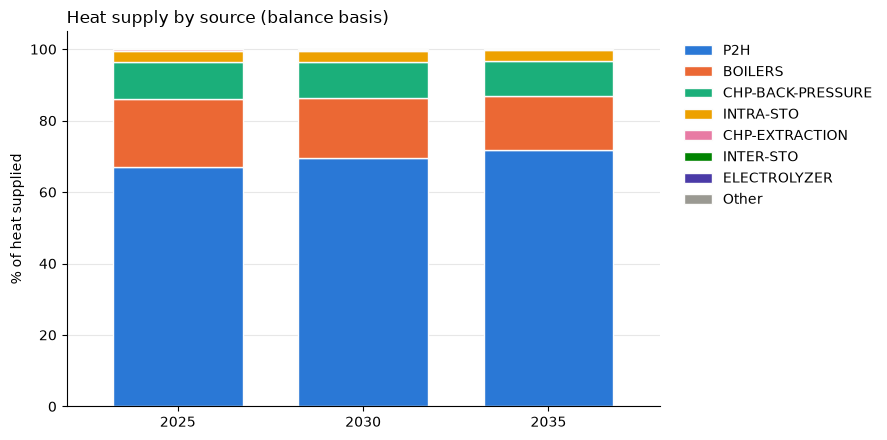

In [5]:
# 7.3 Heat balance per area and time slice (MWh): supply = demand + net export
# H_BALANCE_YCRAST has no row for the waste heat of electrolysers (a heat producer in PRO_YCRAGFST), so it is added to
# the supply here. Without it the balance is short by 1 - 3 % of the heat in countries with electrolysis.
h_bal = balance(get("H_BALANCE_YCRAST"), "Area")
elz = get("PRO_YCRAGFST").query("Commodity == 'HEAT' and Technology == 'ELECTROLYZER'")
elz = elz.groupby(["Year", "Country", "Area", "Season", "Time"])["Value"].sum()
h_bal["Supply"] += elz.reindex(h_bal.index).fillna(0)
h_bal["Residual"] = h_bal["Supply"] - h_bal["Demand"] - h_bal["NetExport"]
orphan = (~elz.index.isin(h_bal.index)).sum()                  # electrolyser heat in an area with no balance row

rel = h_bal["Residual"].abs() / h_bal[["Supply", "Demand"]].max(axis=1).clip(lower=1)
record("Balance", "Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice",
       "FAIL" if orphan else grade(rel.max(), 1e-6, 1e-3),
       f"largest residual {h_bal['Residual'].abs().max():.3g} MWh ({rel.max():.1e} of the flow)"
       + (f"; {orphan} electrolyser heat entries have no matching balance row" if orphan else ""))
unmet = h_bal["Residual"] < -1          # demand + exports larger than supply by more than 1 MWh
record("Balance", "Heat: no area-slice with unmet demand", "FAIL" if unmet.any() else "PASS",
       f"{unmet.sum()} of {len(h_bal)} area-slices short of supply")

# Heat supply by source on the balance basis (% of all heat supplied); the balance closes, so this is also the demand mix
h_raw = get("H_BALANCE_YCRAST")
h_raw = h_raw[(h_raw["Unit"] == "MWh") & ~h_raw["Technology"].str.startswith("DEMAND")
              & ~h_raw["Technology"].isin(["NETEXPORT", "CURTAILMENT"])]
h_src = h_raw.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
h_src["ELECTROLYZER"] = elz.groupby("Year").sum().reindex(h_src.index).fillna(0)       # the source missing in the table
stacked_by_label(h_src.div(h_src.sum(axis=1), axis=0) * 100, "Heat supply by source (balance basis)", "% of heat supplied", n=7)
plt.tight_layout(); plt.show()


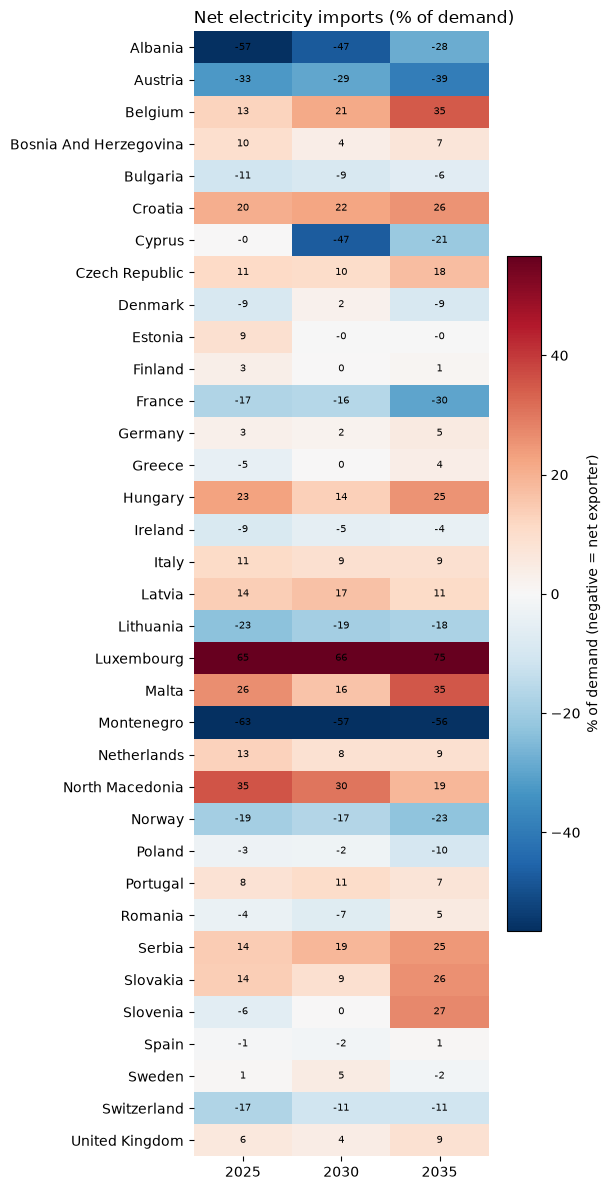

In [6]:
# 7.4 Is the electricity demand of every country supplied? Coverage = (domestic supply - net export) / demand
el_cy = el_bal.groupby(["Year", "Country"])[["Supply", "Demand", "NetExport"]].sum()
coverage = ((el_cy["Supply"] - el_cy["NetExport"]) / el_cy["Demand"] * 100).unstack("Year")        # % of demand served
imports = (-el_cy["NetExport"] / el_cy["Demand"] * 100).unstack("Year")                           # >0 net importer, <0 net exporter
record("Balance", "Electricity: demand of every country served (domestic supply + net imports)",
       grade((coverage - 100).abs().max().max() / 100, 1e-6, 1e-3),
       f"coverage {coverage.min().min():.4f} - {coverage.max().max():.4f} % across {len(coverage)} countries and {coverage.shape[1]} years")

# Net import dependence per country and year (% of electricity demand): red = importer, blue = exporter
fig, ax = plt.subplots(figsize=(max(6, 1.0 * imports.shape[1] + 3), 0.3 * len(imports) + 1.5))
lim = max(10, np.nanpercentile(imports.abs().values, 95))
im = ax.imshow(imports.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(imports.shape[1])); ax.set_xticklabels(imports.columns)
ax.set_yticks(range(len(imports))); ax.set_yticklabels([clean_name(c) for c in imports.index])
for i in range(imports.shape[0]):
    for j in range(imports.shape[1]):
        ax.text(j, i, f"{imports.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Net electricity imports (% of demand)", loc="left")
for side in ax.spines.values(): side.set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of demand (negative = net exporter)")
plt.tight_layout(); plt.show()


In [7]:
# 7.5 Physical limits: capacity, dispatch, transmission, storage and curtailment must respect their bounds
cap, pro = get("G_CAP_YCRAF"), get("PRO_YCRAGF")

cap_gen = cap.groupby(["Year", "Generation", "Region", "Area"])["Value"].sum()
record("Limits", "Installed capacity never negative", "FAIL" if (cap_gen < -1e-6).any() else "PASS",
       f"{(cap_gen < -1e-6).sum()} generators below zero (smallest {cap_gen.min():.2g} GW)")
record("Limits", "Production never negative", "FAIL" if (pro["Value"] < -1e-6).any() else "PASS",
       f"{(pro['Value'] < -1e-6).sum()} generator rows below zero")

# Annual production <= installed capacity x 8760 h. Hydrogen is skipped: reforming capacity is stated on a fuel basis
for commodity in ["ELECTRICITY", "HEAT"]:
    c = cap[cap["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    p = pro[pro["Commodity"] == commodity].groupby(["Year", "Generation"])["Value"].sum()
    c = c.reindex(p.index).fillna(0)
    no_cap = ((p > 1e-6) & (c <= 1e-9)).sum()
    util = (p[c > 1e-9] / (c[c > 1e-9] * 8.76))                       # TWh / (GW x 8.76 TWh per GW-year)
    record("Limits", f"{commodity.title()}: production within capacity x 8760 h",
           "FAIL" if no_cap else grade(util.max() - 1, 1e-3, 5e-2),
           f"highest utilisation {util.max():.1%}; {no_cap} generators produce without installed capacity")

# Transmission: annual flow <= capacity x 8760 h (electricity lines and hydrogen pipelines)
for label, flow_sym, cap_sym in [("Electricity", "X_FLOW_YCR", "X_CAP_YCR"), ("Hydrogen", "XH2_FLOW_YCR", "XH2_CAP_YCR")]:
    f = get(flow_sym).groupby(["Year", "From", "To"])["Value"].sum()
    c = get(cap_sym).groupby(["Year", "From", "To"])["Value"].sum().reindex(f.index)
    u = f / (c * 8.76)
    no_cap = (f.gt(1e-6) & c.fillna(0).le(1e-9)).sum()
    record("Limits", f"{label} transmission: flow within capacity x 8760 h",
           "FAIL" if no_cap else grade(u[c > 1e-9].max() - 1, 1e-3, 5e-2),
           f"highest line utilisation {u[c > 1e-9].max():.1%}; {no_cap} links carry flow without capacity")

# Storage: level between zero and the installed storage capacity (level in MWh, capacity in GWh)
lvl = get("STORAGE_LEVEL").groupby(["Year", "Generation", "Area"])["Value"].agg(["min", "max"])
sto = get("G_STO_YCRAF").groupby(["Year", "Generation", "Area"])["Value"].sum() * 1000
lvl["cap"] = sto.reindex(lvl.index).fillna(0)                         # no capacity record = zero capacity
over = lvl["max"] > lvl["cap"] * 1.001 + 1e-3                         # 1e-3 MWh absorbs solver round-off
below = lvl["min"] < -1e-3
record("Limits", "Storage level between zero and capacity", "FAIL" if (over | below).any() else "PASS",
       f"{over.sum()} storages above capacity, {below.sum()} below zero, of {len(lvl)}")

# Curtailment of wind and solar is a positive quantity (hydro reservoirs net to about zero and are excluded)
curt_vre = get("CURT_YCRAGF").query("Technology in ['WIND-ON', 'WIND-OFF', 'SOLAR-PV']")
record("Limits", "Wind and solar curtailment not negative", "FAIL" if (curt_vre["Value"] < -1e-6).any() else "PASS",
       f"{(curt_vre['Value'] < -1e-6).sum()} rows below zero")


In [8]:
# 7.6 Plausibility: prices, plant efficiencies and missing values
price = get("EL_PRICE_YCR")
ok = price["Value"].between(-50, 500)
record("Plausibility", "Electricity prices in -50 .. 500 Money/MWh", "PASS" if ok.all() else "WARN",
       f"range {price['Value'].min():.1f} .. {price['Value'].max():.1f}, mean {price['Value'].mean():.1f}; "
       f"{(~ok).sum()} of {len(price)} region-years outside")

# Implied efficiency of combustion plants = output (all commodities) / fuel input. Above 100 % is a WARN, not a FAIL:
# it repeats identically in every year and area, so it comes from the technology input data, not from the solution
COMBUSTION = ["CONDENSING", "CHP-BACK-PRESSURE", "CHP-EXTRACTION", "BOILERS"]
out = pro.groupby(["Year", "Generation", "Technology"])["Value"].sum()
fuel_in = get("F_CONS_YCRA").groupby(["Year", "Generation", "Technology"])["Value"].sum()
eff = (out / fuel_in).replace([np.inf], np.nan).dropna()
eff = eff[eff.index.get_level_values("Technology").isin(COMBUSTION)]
above = sorted(set(eff[eff > 1.001].index.get_level_values("Generation")))
record("Plausibility", "Combustion plants: output / fuel input <= 100 %", "WARN" if above else "PASS",
       f"highest implied efficiency {eff.max():.1%} ({eff.idxmax()[1]}, {eff.idxmax()[0]}); median {eff.median():.1%}"
       + (f"; above 100 %: {', '.join(above[:5])}{' ...' if len(above) > 5 else ''} - check the technology data (condensing boilers can exceed 100 % on an LHV basis)" if above else ""))

# Missing values in the result tables used above
frames = {"production": pro, "capacity": cap, "price": price, "electricity balance": el_bal.reset_index(),
          "heat balance": h_bal.reset_index()}
numeric = ["Value", "Supply", "Demand", "NetExport", "Residual"]
nans = {k: int(v[[c for c in numeric if c in v]].isna().sum().sum()) for k, v in frames.items()}
record("Plausibility", "No missing values in the result tables", "FAIL" if any(nans.values()) else "PASS",
       ", ".join(f"{k}: {n}" for k, n in nans.items() if n) or "none found")


In [9]:
# 7.7 Summary of all validation checks
checks = pd.DataFrame(CHECKS)
print(checks["Status"].value_counts().reindex(["PASS", "INFO", "WARN", "FAIL"]).dropna().astype(int).to_dict())
colors = {"PASS": "#d8f0e3", "INFO": "#e6e6e6", "WARN": "#fbe9b7", "FAIL": "#f6c9c8"}
styler = checks.style.hide(axis="index").set_properties(subset=["Check", "Detail"], **{"text-align": "left"})
paint = getattr(styler, "map", None) or styler.applymap                  # Styler.map needs pandas >= 2.1
display(paint(lambda s: f"background-color: {colors.get(s, '')}", subset=["Status"]))


{'PASS': 17, 'INFO': 1, 'WARN': 1}


Section,Check,Status,Detail
Run,Time resolution,INFO,8 seasons x 24 time steps = 192 slices per year
Run,All solves optimal,PASS,"3 solves, all Optimal / Normal completion"
Run,Log covers the years of the results,PASS,log and results list the same years
Balance,Electricity: supply = demand + net export in every region and time slice,PASS,largest residual 1.4e-09 MWh (3.4e-13 of the flow)
Balance,Electricity: no region-slice with unmet demand,PASS,0 of 26496 region-slices short of supply
Balance,Heat: supply (incl. electrolyser waste heat) = demand + net export in every area and time slice,PASS,largest residual 2.58e-09 MWh (3.0e-11 of the flow)
Balance,Heat: no area-slice with unmet demand,PASS,0 of 236219 area-slices short of supply
Balance,Electricity: demand of every country served (domestic supply + net imports),PASS,coverage 100.0000 - 100.0000 % across 35 countries and 3 years
Limits,Installed capacity never negative,PASS,0 generators below zero (smallest -4.5e-16 GW)
Limits,Production never negative,PASS,0 generator rows below zero


## 1. Total demand
Annual demand per carrier, split by the `Category` column of each result:
`EXOGENOUS` is the final demand given as input, the `ENDO_*` categories are demand created inside the model
(EV charging, electric heating, electrolysis, CCS, storage charging, fuel cells), and the `*_LOSSES` categories are network losses.
EV charging is part of the electricity demand (`ENDO_EV`) and is also shown on its own.

In [10]:
# 1.0 Demand categories folded into groups (shared colours across the carriers)
DEMAND_GROUP = {
    "EXOGENOUS": "Final demand",
    "ENDO_EV": "EV charging",
    "ENDOGENOUS_ELECT2HEAT": "Electric heating",
    "ENDO_H2": "Electrolysis",
    "ENDO_CCS": "CCS",
    "ENDO_INTRASTO": "Storage charging", "ENDO_INTERSTO": "Storage charging",
    "ENDO_FUELCELL": "Fuel cell / other", "ENDO_OTHERTRANS": "Fuel cell / other",
    "DIST_LOSSES": "Losses", "TRANS_LOSSES": "Losses",
}
DEMAND_COLORS = {"Final demand": "#2a78d6", "EV charging": "#eb6834", "Electric heating": "#1baf7a",
                 "Electrolysis": "#eda100", "CCS": "#e87ba4", "Storage charging": "#008300",
                 "Fuel cell / other": "#4a3aa7", "Losses": "#9a9992"}

In [11]:
# 1.1 Load and aggregate demand by carrier and category
demand_sources = {
    "Electricity": get("EL_DEMAND_YCR"),
    "Heat": get("H_DEMAND_YCRA"),
    "Hydrogen": get("H2_DEMAND_YCR"),
}

demand = {}
for name, df in demand_sources.items():
    demand[name] = (
        df.assign(Group=df["Category"].map(DEMAND_GROUP))
          .groupby(["Year", "Group"])["Value"]
          .sum()
          .unstack("Group")
          .fillna(0)
    )

ev = (
    demand_sources["Electricity"]
    .loc[lambda d: d["Category"] == "ENDO_EV"]
    .groupby("Year")["Value"]
    .sum()
    .rename("EV charging")
    .reindex(demand["Electricity"].index, fill_value=0)      # years without EV demand count as 0
)

summary_demand = pd.DataFrame({
    name: table.sum(axis=1)
    for name, table in demand.items()
})
summary_demand["EV charging (part of electricity)"] = ev

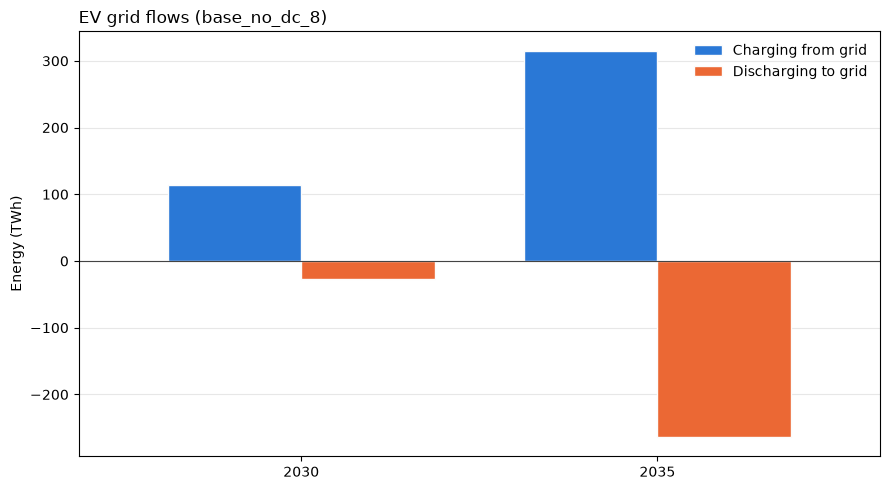

In [12]:
# 1.2 EV grid exchange components: charging from the grid, discharging to the grid, and net exchange
EV_COMPONENTS = {"Charging from grid": ("EV_G2V_Y", 1), "Discharging to grid": ("EV_V2G_Y", -1), "Net grid exchange": ("EV_NET_Y", 1)}
ev_components = {}
missing_ev_components = []
for label, (symbol, sign) in EV_COMPONENTS.items():
    try:
        table = get(symbol)
    except Exception as exc:
        missing_ev_components.append(f"{symbol}: {exc}")
        continue
    if table.empty:
        missing_ev_components.append(f"{symbol}: no rows for scenario {SCENARIO}")
        continue
    ev_components[label] = sign * table.groupby("Year")["Value"].sum()
if missing_ev_components:
    raise RuntimeError("Missing EV component outputs. Rerun the scenario after updating OUTPUT_SUMMARY.inc: " + "; ".join(missing_ev_components))
ev_components = pd.DataFrame(ev_components).sort_index()
ev_grid_flows = ev_components[["Charging from grid", "Discharging to grid"]]
ax = ev_grid_flows.plot.bar(figsize=(max(9, 0.5 * len(ev_grid_flows) + 5), 5), color=["#2a78d6", "#eb6834"], width=0.75, edgecolor="#fcfcfb")
ax.axhline(0, color="#444444", linewidth=0.8)
ax.set_title(f"EV grid flows ({SCENARIO})", loc="left")
ax.set_ylabel("Energy (TWh)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=xrot(len(ev_grid_flows)))
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

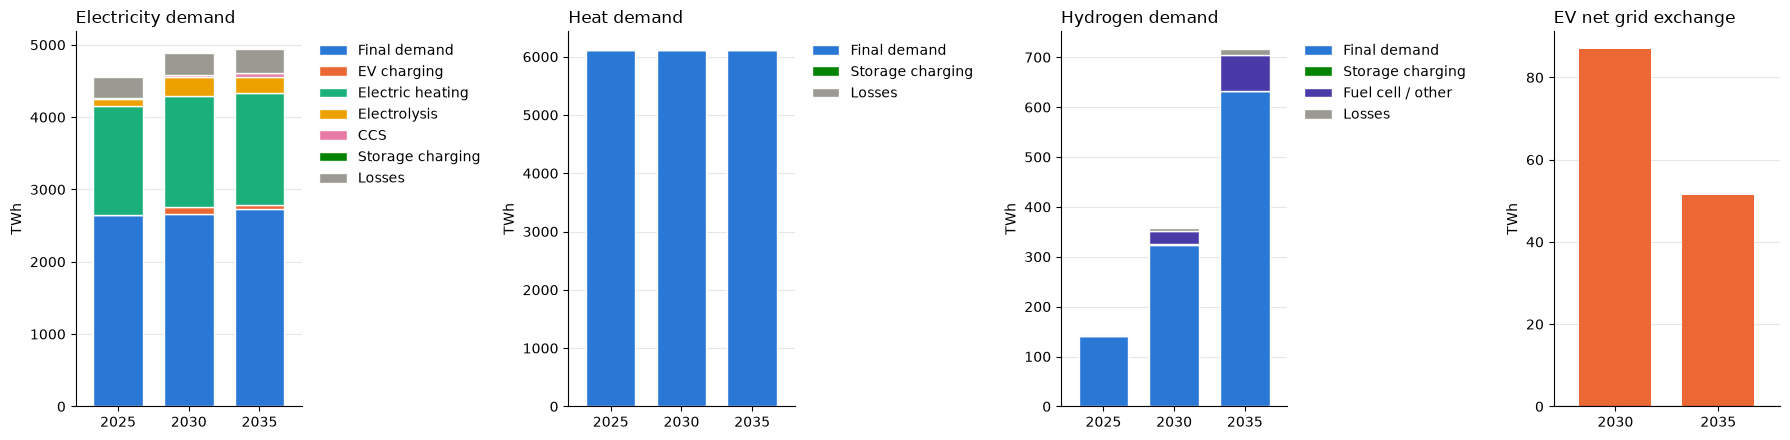

In [13]:
# 1.3 Total demand per carrier and category (TWh), plus net EV grid exchange
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, (name, table) in zip(axes[:3], demand.items()):
    stacked_bar(table, DEMAND_COLORS, f"{name} demand", "TWh", ax=ax)
ev_components["Net grid exchange"].plot.bar(ax=axes[3], color=DEMAND_COLORS["EV charging"], width=0.7)
axes[3].axhline(0, color="#444444", linewidth=0.8)
axes[3].set_title("EV net grid exchange", loc="left"); axes[3].set_ylabel("TWh"); axes[3].set_xlabel("")
axes[3].tick_params(axis="x", rotation=xrot(len(ev_components))); axes[3].grid(axis="y", alpha=0.3); axes[3].set_axisbelow(True)
for side in ("top", "right"): axes[3].spines[side].set_visible(False)
plt.tight_layout()
plt.show()

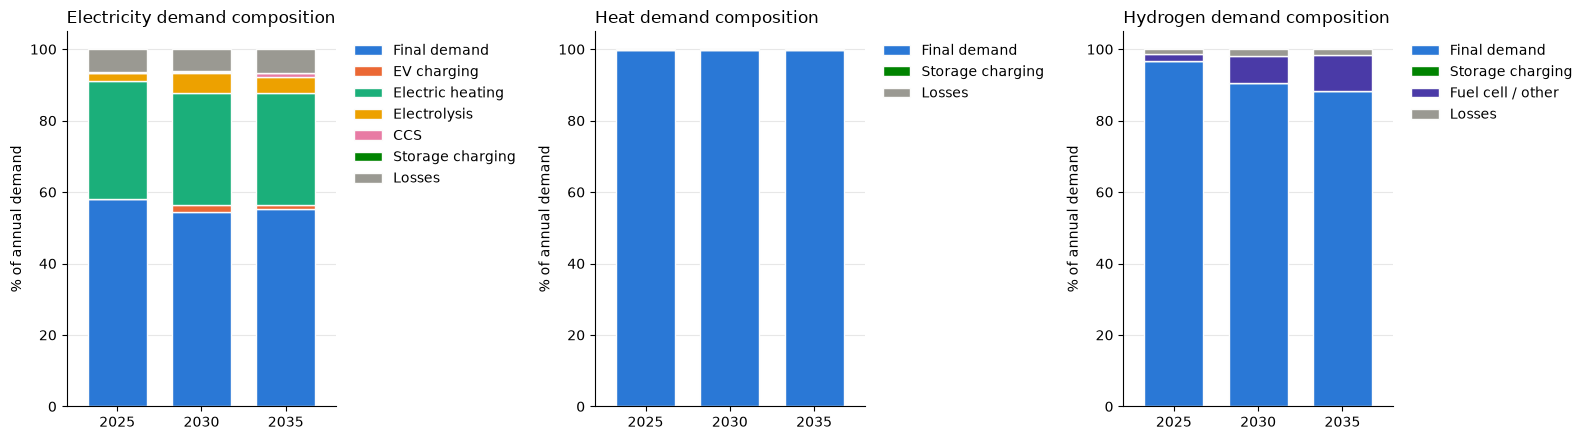

In [14]:
# 1.3 Demand composition (% of each carrier's annual demand)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, table) in zip(axes, demand.items()):
    share = table.div(table.sum(axis=1), axis=0) * 100
    stacked_bar(share, DEMAND_COLORS, f"{name} demand composition", "% of annual demand", ax=ax)
plt.tight_layout(); plt.show()

In [15]:
# 1.5 Annual energy-balance Sankey diagram (TWh)
# Technology groups feed carriers, which feed final demand.
SANKEY_YEAR = max(get("PRO_YCRAGF")["Year"])
sankey_carriers = ["ELECTRICITY", "HEAT", "HYDROGEN"]
sankey_names = {"ELECTRICITY": "Electricity", "HEAT": "Heat", "HYDROGEN": "Hydrogen"}

sankey_pro = get("PRO_YCRAGF").query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers").copy()
sankey_pro["Source"] = tech_group(sankey_pro, unpack=True)
sankey_pro = sankey_pro.groupby(["Commodity", "Source"])["Value"].sum().reset_index()

sankey_dem = pd.concat([
    get("EL_DEMAND_YCR").assign(Commodity="ELECTRICITY"),
    get("H_DEMAND_YCRA").assign(Commodity="HEAT"),
    get("H2_DEMAND_YCR").assign(Commodity="HYDROGEN"),
], ignore_index=True).query("Year == @SANKEY_YEAR and Commodity in @sankey_carriers")
sankey_dem = sankey_dem.groupby("Commodity")["Value"].sum()

source_labels = [f"{row.Commodity.title()}: {row.Source}" for row in sankey_pro.itertuples()]
carrier_labels = [sankey_names[c] for c in sankey_carriers]
sink_labels = [f"{sankey_names[c]} final demand" for c in sankey_carriers]
labels = source_labels + carrier_labels + sink_labels
carrier_index = {c: len(source_labels) + i for i, c in enumerate(sankey_carriers)}
sink_index = {c: len(source_labels) + len(carrier_labels) + i for i, c in enumerate(sankey_carriers)}
source_index = {(row.Commodity, row.Source): i for i, row in enumerate(sankey_pro.itertuples())}

links = [(source_index[(row.Commodity, row.Source)], carrier_index[row.Commodity], row.Value) for row in sankey_pro.itertuples() if row.Value > 0]
for commodity in sankey_carriers:
    supply = sankey_pro.loc[sankey_pro["Commodity"] == commodity, "Value"].sum()
    demand_value = float(sankey_dem.get(commodity, 0))
    if demand_value > 0:
        links.append((carrier_index[commodity], sink_index[commodity], demand_value))
    residual = supply - demand_value
    if residual > 1e-9:
        labels.append(f"{sankey_names[commodity]} surplus / exports")
        links.append((carrier_index[commodity], len(labels) - 1, residual))
    elif residual < -1e-9:
        labels.append(f"{sankey_names[commodity]} net imports")
        links.append((len(labels) - 1, carrier_index[commodity], -residual))

fig = go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(label=labels, pad=18, thickness=18, line=dict(color="rgba(80,80,80,0.35)", width=0.5)),
    link=dict(source=[x[0] for x in links], target=[x[1] for x in links], value=[x[2] for x in links]),
))
fig.update_layout(title=f"Annual energy balance, {SANKEY_YEAR} ({SCENARIO})", height=720, width=1250,
                  font=dict(size=11), margin=dict(l=10, r=10, t=55, b=10))
fig.show()


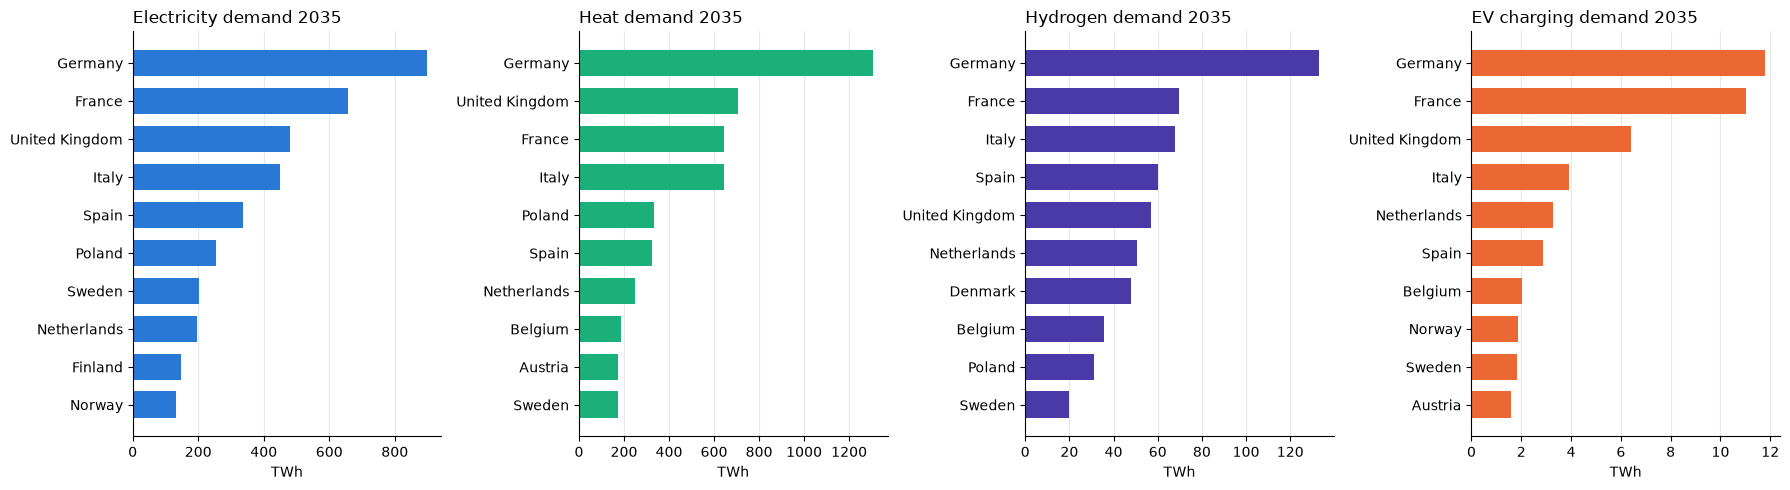

In [16]:
# 1.4 Demand per country in the last solved year (TWh): the 10 largest countries for each carrier
el_d, h_d, h2_d = get("EL_DEMAND_YCR"), get("H_DEMAND_YCRA"), get("H2_DEMAND_YCR")
last = el_d["Year"].max()
per_country = {
    "Electricity": (el_d[el_d["Year"] == last].groupby("Country")["Value"].sum(), "#2a78d6"),
    "Heat": (h_d[h_d["Year"] == last].groupby("Country")["Value"].sum(), "#1baf7a"),
    "Hydrogen": (h2_d[h2_d["Year"] == last].groupby("Country")["Value"].sum(), "#4a3aa7"),
    "EV charging": (el_d[(el_d["Year"] == last) & (el_d["Category"] == "ENDO_EV")].groupby("Country")["Value"].sum(),
                    DEMAND_COLORS["EV charging"]),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (name, (series, color)) in zip(axes, per_country.items()):
    s = series.sort_values(ascending=False).head(10).iloc[::-1]          # largest on top
    ax.barh([clean_name(c) for c in s.index], s.values, color=color, height=0.7)
    ax.set_title(f"{name} demand {last}", loc="left"); ax.set_xlabel("TWh")
    ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

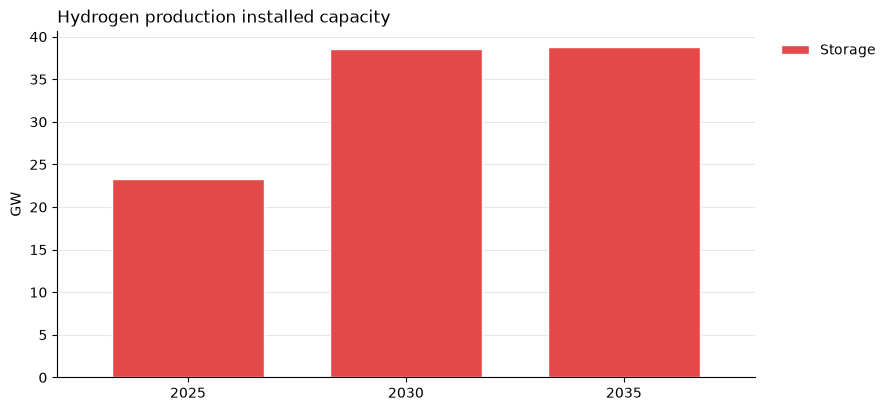

In [17]:
# 1.4 Hydrogen production capacity
cap = get("G_CAP_YCRAF")
hydrogen_cap = cap[cap["Commodity"] == "HYDROGEN"].copy()
hydrogen_cap["Technology group"] = hydrogen_cap["Technology"].map(TECH_GROUP).fillna("Other")
hydrogen_cap = hydrogen_cap.groupby(["Year", "Technology group"])["Value"].sum().unstack("Technology group").fillna(0)
stacked_bar(hydrogen_cap, GROUP_COLORS_UNPACKED, "Hydrogen production installed capacity", "GW")
plt.show()

## 2. Total capacity mix
`G_CAP_YCRAF` splits capacity into `EXOGENOUS` (existing / given), `ENDOGENOUS` (investments) and `DECOMMISSIONING` (negative).
The installed capacity of a year is the sum of the three. One chart per output commodity.

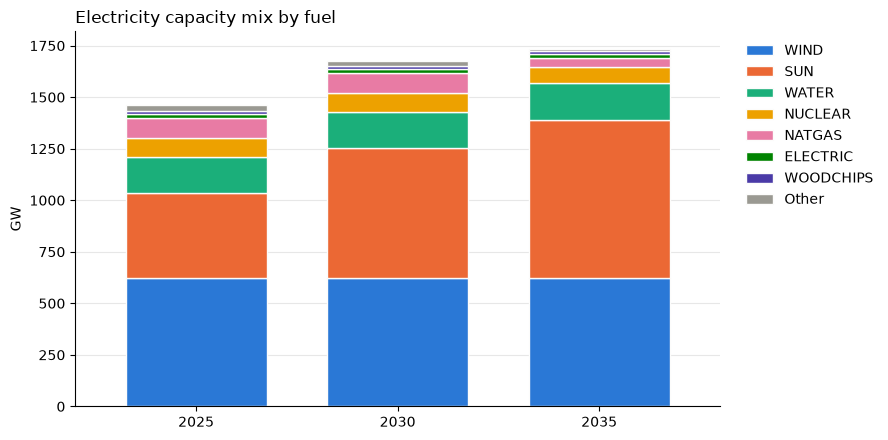

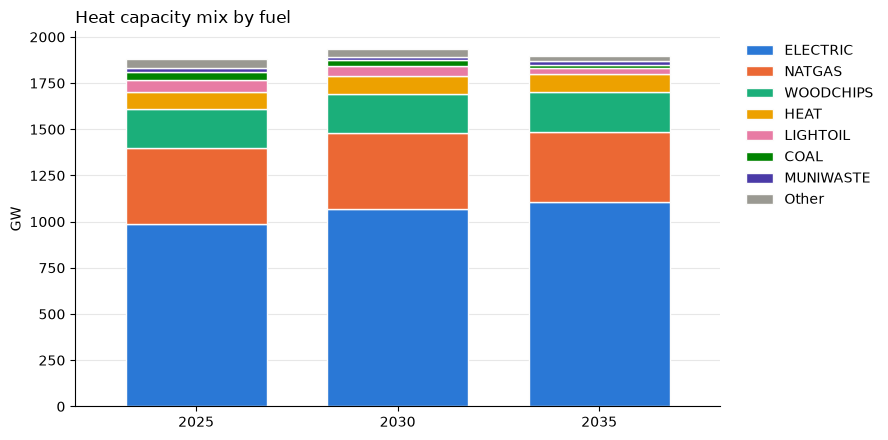

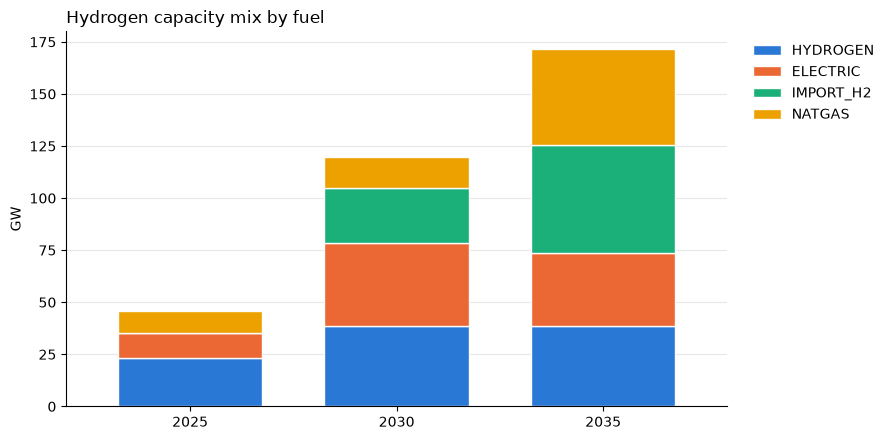

In [18]:
# 2.1 Installed capacity per fuel per year = exogenous + endogenous + decommissioning (GW)
cap = get("G_CAP_YCRAF")
for commodity in ["ELECTRICITY", "HEAT", "HYDROGEN"]:
    table = cap[cap["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} capacity mix by fuel", "GW")
    plt.tight_layout(); plt.show()


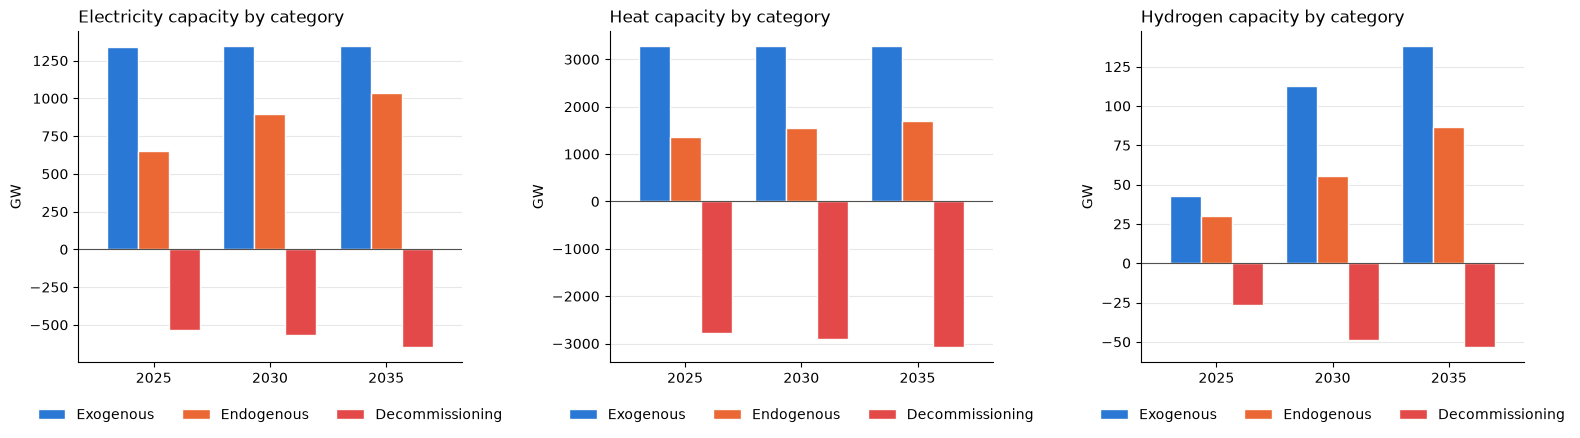

In [19]:
# 2.2 Where does the capacity come from? Exogenous, endogenous (investments) and decommissioning (GW)
CAT_COLORS = {"EXOGENOUS": "#2a78d6", "ENDOGENOUS": "#eb6834", "DECOMMISSIONING": "#e34948"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, commodity in zip(axes, ["ELECTRICITY", "HEAT", "HYDROGEN"]):
    t = cap[cap["Commodity"] == commodity].groupby(["Year", "Category"])["Value"].sum().unstack("Category").fillna(0)
    t = t[[c for c in CAT_COLORS if c in t.columns]]
    t.plot.bar(ax=ax, color=[CAT_COLORS[c] for c in t.columns], width=0.8, edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(f"{commodity.title()} capacity by category", loc="left"); ax.set_ylabel("GW"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=xrot(len(t))); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    ax.legend([clean_name(c) for c in t.columns], frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, -0.1), ncol=3)
    ax.axhline(0, color="#52514e", linewidth=0.8)          # zero line drawn after the legend exists
plt.tight_layout(); plt.show()

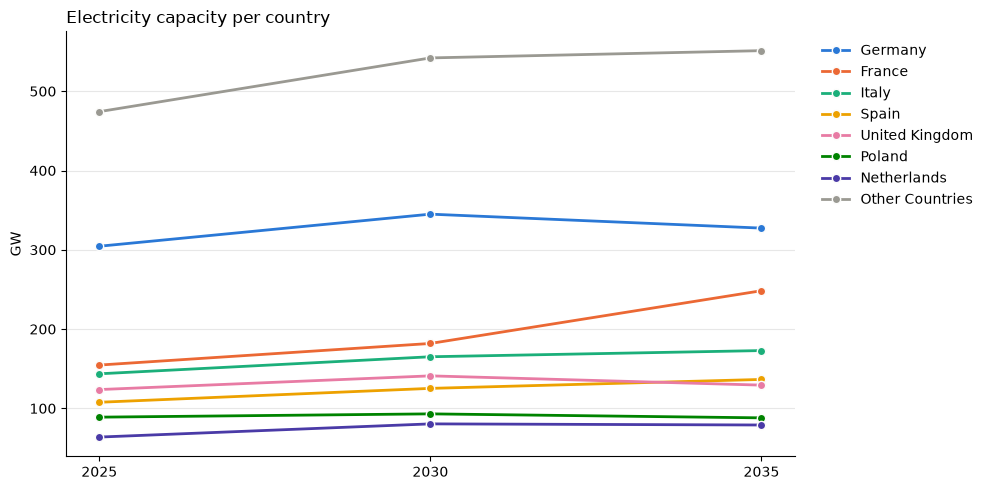

In [20]:
# 2.3 Electricity capacity per country (GW): line plot of the 7 largest countries, the rest summed as "Other countries"
cap_el = cap[cap["Commodity"] == "ELECTRICITY"]
by_country = cap_el.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0)
by_country = by_country.sort_values(by_country.columns[-1], ascending=False)

other = by_country.iloc[7:].sum().to_frame("Other countries").T
plot_df = pd.concat([by_country.head(7), other]).T            # rows = years, columns = lines

palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#9a9992"]
fig, ax = plt.subplots(figsize=(10, 5))
for name, color in zip(plot_df.columns, palette):
    ax.plot(plot_df.index, plot_df[name], marker="o", markersize=6, linewidth=2, color=color,
            markeredgecolor="#fcfcfb", label=name.replace("_", " ").title())
ax.set_title("Electricity capacity per country", loc="left")
ax.set_ylabel("GW"); ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()


## 3. Total energy dispatched mix
`PRO_YCRAGF` is the annual production per generator (TWh), split by output commodity.

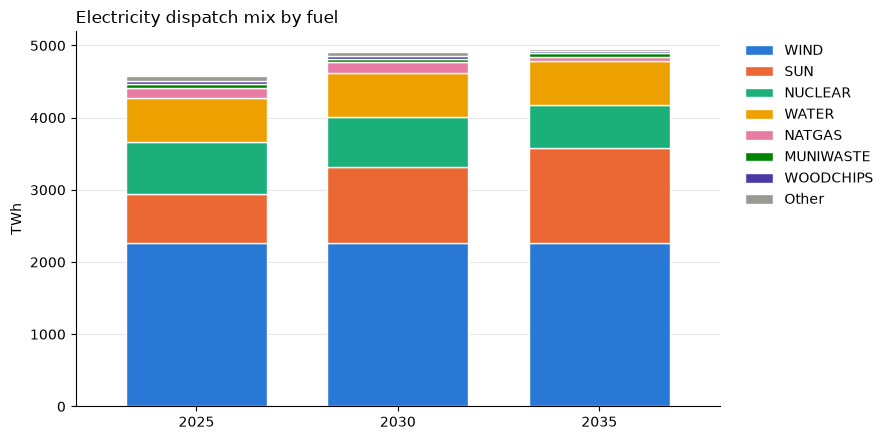

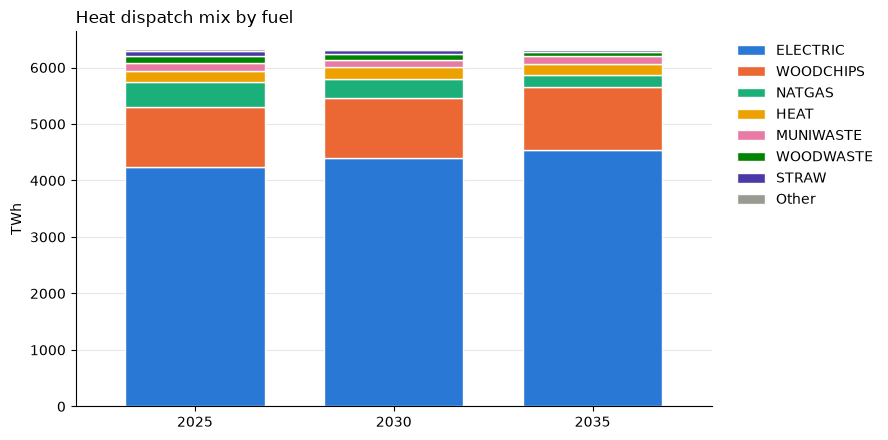

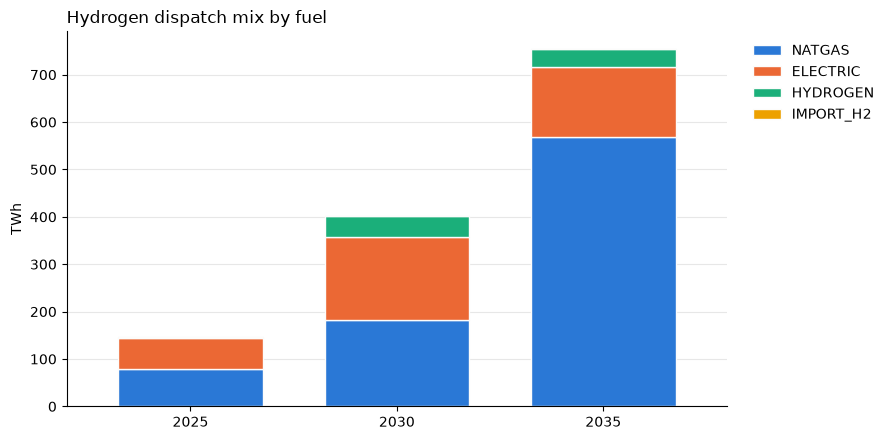

In [21]:
# 3.1 Annual production by fuel (TWh) for each commodity
pro = get("PRO_YCRAGF")
for commodity in ["ELECTRICITY", "HEAT", "HYDROGEN"]:
    table = pro[pro["Commodity"] == commodity].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
    stacked_by_label(table, f"{commodity.title()} dispatch mix by fuel", "TWh")
    plt.tight_layout(); plt.show()


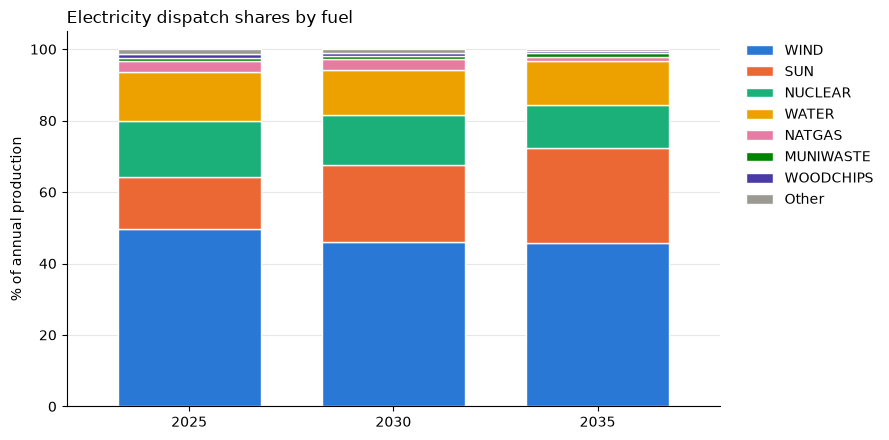

In [22]:
# 3.2 Electricity dispatch shares by fuel (% of annual electricity production)
el = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(el.div(el.sum(axis=1), axis=0) * 100, "Electricity dispatch shares by fuel", "% of annual production")
plt.tight_layout(); plt.show()

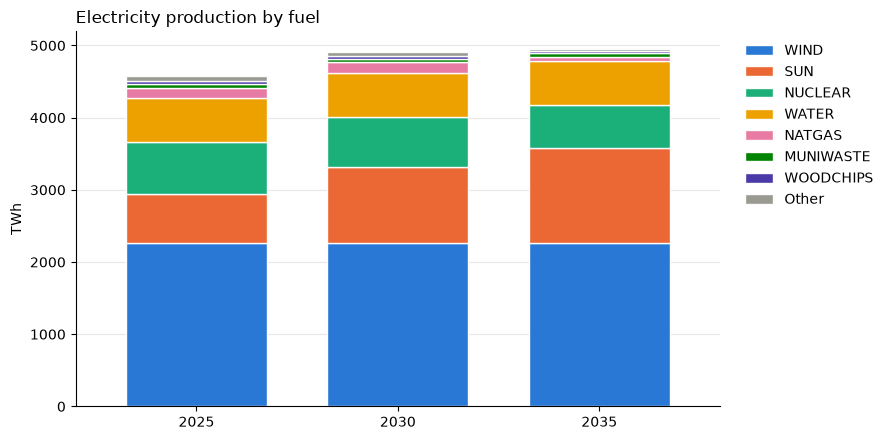

In [23]:
# 3.3 Electricity production by fuel (TWh): the 7 largest fuels, the rest summed as "Other"
fuel = pro[pro["Commodity"] == "ELECTRICITY"].groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel, "Electricity production by fuel", "TWh")
plt.tight_layout(); plt.show()

Found MainResults in c:\Balmorel\base_no_dc_8\model\MainResults.gdx


c:\Users\gdada\anaconda3\envs\pybalmorel\Lib\site-packages\pyogrio\core.py:38: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


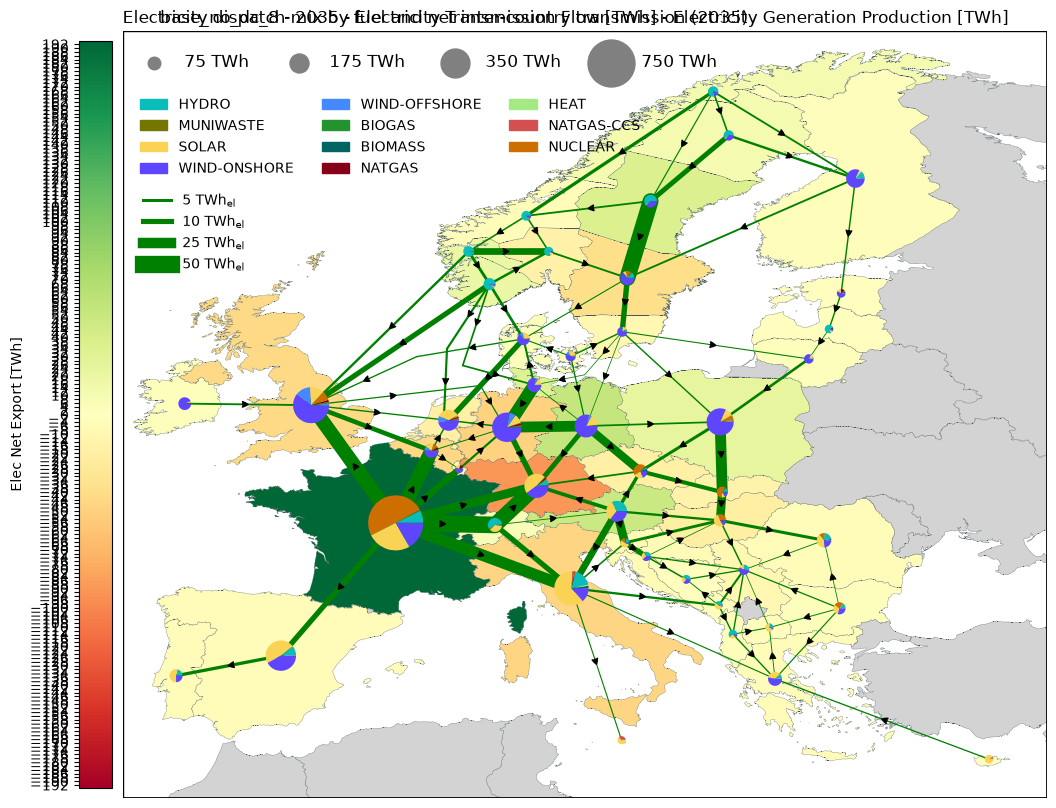

In [24]:
# 3.4 Electricity dispatch mix by fuel per country and net inter-country transmission
# FlowYear shows the annual net flow on each electricity transmission line.
# Compatibility for pybalmorel 1.2.3 with Matplotlib versions where cm.get_cmap was removed.
if not hasattr(plt.cm, "get_cmap"):
    plt.cm.get_cmap = plt.colormaps.get_cmap
MAP_YEAR = int(max(pro["Year"]))
fig, ax = res.plot_map(
    scenario=SCENARIO,
    year=MAP_YEAR,
    commodity="Electricity",
    lines="FlowYear",
    generation="Production",
    generation_var="FFF",
    background="Elec Net Export",
)
ax.set_title(f"Electricity dispatch mix by fuel and net inter-country transmission ({MAP_YEAR})", loc="left")
plt.show()

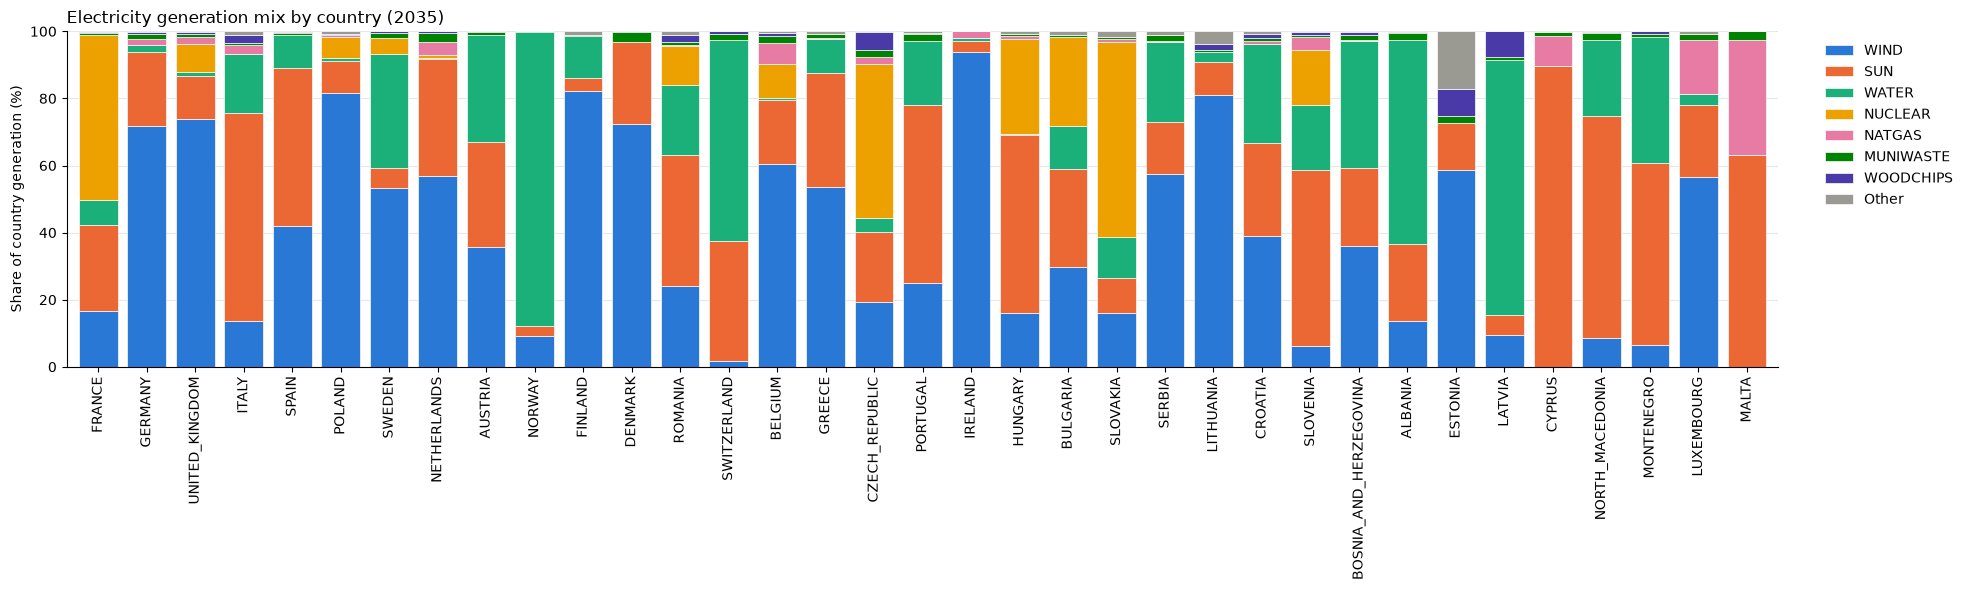

In [25]:
# 3.5 Electricity generation mix by country in 2035
# Regions belonging to the same country are aggregated before calculating the mix.
COUNTRY_MIX_YEAR = 2035
country_el = pro[(pro["Year"].astype(str) == str(COUNTRY_MIX_YEAR)) & (pro["Commodity"] == "ELECTRICITY")].copy()
country_mix = country_el.groupby(["Country", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
country_mix = country_mix.loc[country_mix.sum(axis=1).sort_values(ascending=False).index]
country_mix = country_mix.loc[:, country_mix.sum().sort_values(ascending=False).index]
country_mix = country_mix.iloc[:, :7].assign(Other=country_mix.iloc[:, 7:].sum(axis=1))
country_mix_pct = country_mix.div(country_mix.sum(axis=1), axis=0).mul(100)
fuel_colors = dict(zip(country_mix_pct.columns, PALETTE[:7] + [GREY]))
ax = country_mix_pct.plot.bar(stacked=True, figsize=(max(12, 0.45 * len(country_mix_pct) + 4), 6), color=[fuel_colors[c] for c in country_mix_pct.columns], width=0.8, edgecolor="#fcfcfb", linewidth=0.5)
ax.set_title("Electricity generation mix by country (2035)", loc="left")
ax.set_ylabel("Share of country generation (%)")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
for side in ("top", "right"): ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Curtailment
`CURT_YCRAGF` gives the curtailed energy per generator (TWh). Wind and solar values are positive curtailment.
Hydro-reservoir rows contain entries of both signs that net to about zero (reservoir balancing), so they do not add curtailment.

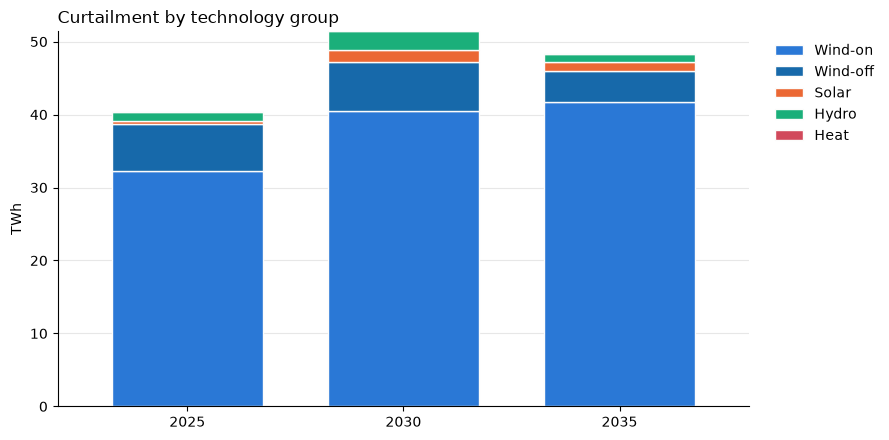

In [26]:
# 4.1 Curtailed energy by technology group (TWh)
curt = get("CURT_YCRAGF")
table = curt.assign(Group=tech_group(curt)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(table, GROUP_COLORS, "Curtailment by technology group", "TWh")
plt.tight_layout(); plt.show()


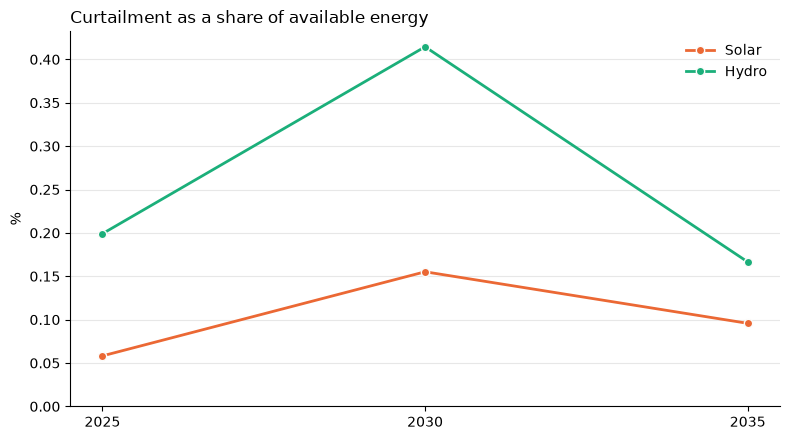

In [27]:
# 4.2 Curtailment as a share of the available energy (dispatched + curtailed), per technology group
prod_g = pro.assign(Group=tech_group(pro)).groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
share = table / (prod_g.reindex_like(table).fillna(0) + table) * 100      # `table` = curtailment by group from 4.1

fig, ax = plt.subplots(figsize=(8, 4.5))
for g in ["Wind", "Solar", "Hydro"]:
    if g in share:
        ax.plot(share.index, share[g], marker="o", markersize=6, linewidth=2, color=GROUP_COLORS[g],
                markeredgecolor="#fcfcfb", label=g)
ax.set_title("Curtailment as a share of available energy", loc="left"); ax.set_ylabel("%"); ax.set_xlabel("")
ax.set_ylim(bottom=0); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
for side in ("top", "right"): ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

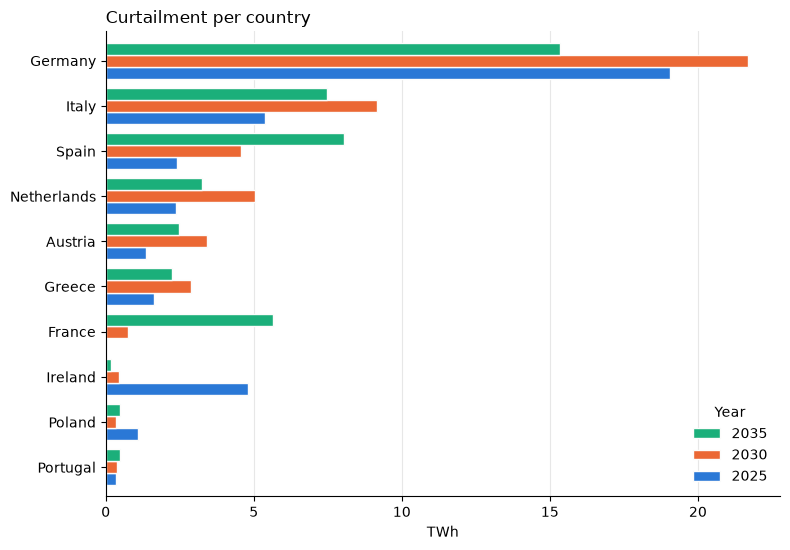

In [28]:
# 4.3 Curtailment per country (TWh): the 10 largest countries
country_bars(curt.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Curtailment per country", "TWh")
plt.tight_layout(); plt.show()

## 5. Total costs
`OBJ_YCR` holds the objective-function cost terms per year and region (Mmoney, the currency of the input data).
Cost terms are folded into five groups.

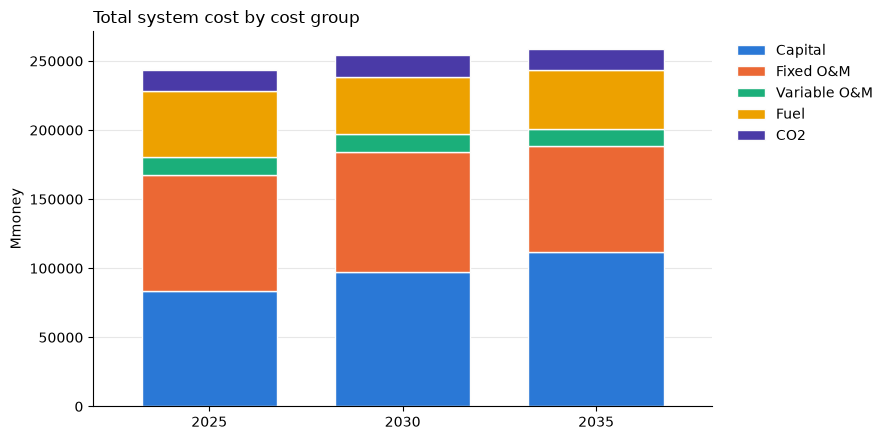

In [29]:
# 5.1 Total system cost per year and cost group (Mmoney)
obj = get("OBJ_YCR")
COST_GROUP = {
    "GENERATION_CAPITAL_COSTS": "Capital", "TRANSMISSION_CAPITAL_COSTS": "Capital", "H2_TRANSMISSION_CAPITAL_COSTS": "Capital",
    "GENERATION_FIXED_COSTS": "Fixed O&M",
    "GENERATION_OPERATIONAL_COSTS": "Variable O&M", "TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "HEAT_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M", "H2_TRANSMISSION_OPERATIONAL_COSTS": "Variable O&M",
    "GENERATION_FUEL_COSTS": "Fuel",
    "GENERATION_CO2_TAX": "CO2", "GENERATION_CO2_TRANSPORT": "CO2",
}
COST_COLORS = {"Capital": "#2a78d6", "Fixed O&M": "#eb6834", "Variable O&M": "#1baf7a", "Fuel": "#eda100", "CO2": "#4a3aa7"}

costs = obj.assign(Group=obj["Category"].map(COST_GROUP).fillna("Other")) \
           .groupby(["Year", "Group"])["Value"].sum().unstack("Group").fillna(0)
stacked_bar(costs, COST_COLORS, "Total system cost by cost group", "Mmoney")
plt.tight_layout(); plt.show()


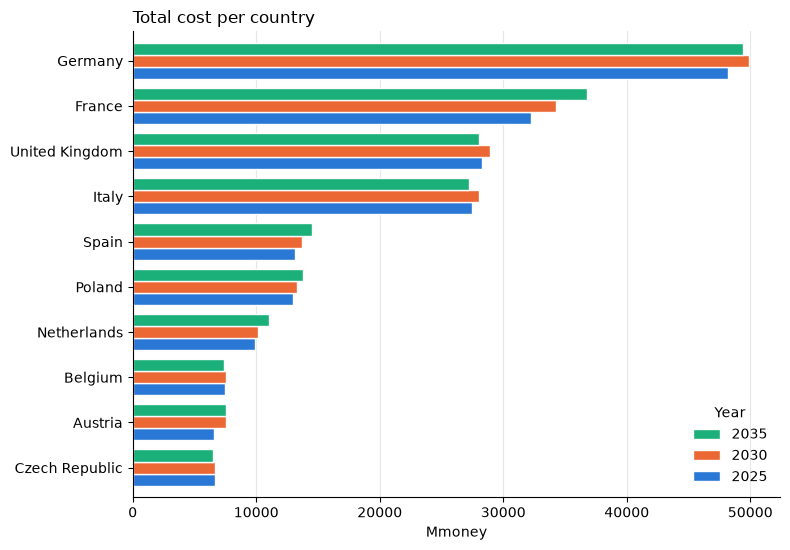

In [30]:
# 5.2 Total cost per country (Mmoney): the 10 largest countries
country_bars(obj.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "Total cost per country", "Mmoney")
plt.tight_layout(); plt.show()

## 6. Total CO2 emissions
`EMI_YCRAG` holds annual CO2 emissions per generator (kton).

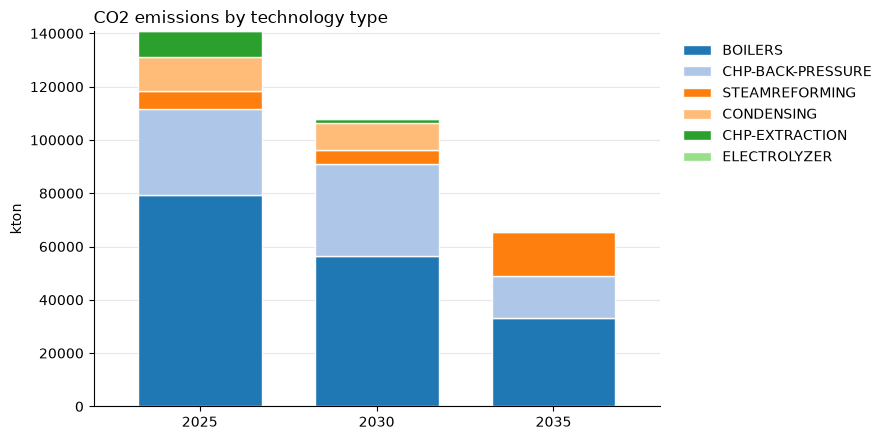

In [31]:
# 6.1 Total CO2 emissions per year by technology type (kton)
emi = get("EMI_YCRAG")
table = emi.groupby(["Year", "Technology"])["Value"].sum().unstack("Technology").fillna(0)
table = table.loc[:, table.sum(axis=0).sort_values(ascending=False).index]
emission_colors = {technology: plt.cm.tab20(i % 20) for i, technology in enumerate(table.columns)}
stacked_bar(table, emission_colors, "CO2 emissions by technology type", "kton")
plt.tight_layout(); plt.show()


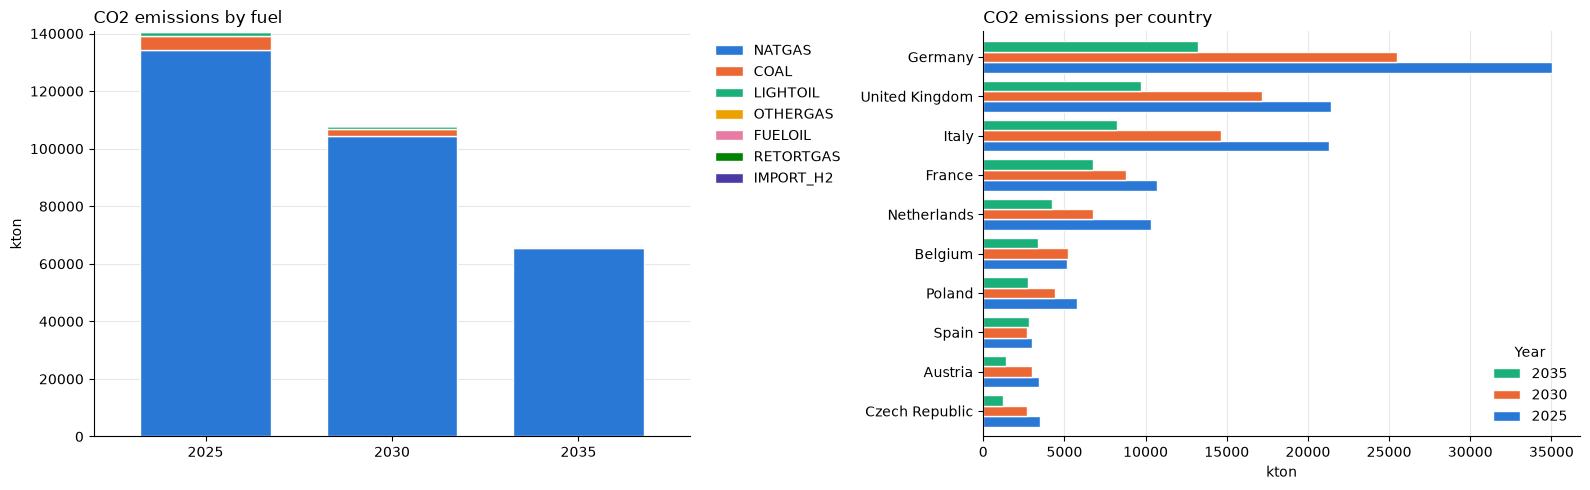

In [32]:
# 6.2 CO2 emissions by fuel (kton) and per country (kton)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fuel_e = emi.groupby(["Year", "Fuel"])["Value"].sum().unstack("Fuel").fillna(0)
stacked_by_label(fuel_e, "CO2 emissions by fuel", "kton", ax=axes[0])
country_bars(emi.groupby(["Country", "Year"])["Value"].sum().unstack("Year").fillna(0),
             "CO2 emissions per country", "kton", ax=axes[1])
plt.tight_layout(); plt.show()

In [33]:
# 6.3 Summary across the topics, per solved year
summary = pd.DataFrame({
    "Electricity demand (TWh)": summary_demand["Electricity"],
    "Heat demand (TWh)": summary_demand["Heat"],
    "Hydrogen demand (TWh)": summary_demand["Hydrogen"],
    "EV charging (TWh)": ev,
    "Electricity capacity (GW)": cap[cap["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Electricity dispatched (TWh)": pro[pro["Commodity"] == "ELECTRICITY"].groupby("Year")["Value"].sum(),
    "Curtailment (TWh)": curt.groupby("Year")["Value"].sum(),
    "Total cost (Mmoney)": obj.groupby("Year")["Value"].sum(),
    "CO2 emissions (kton)": emi.groupby("Year")["Value"].sum(),
}).round(1)


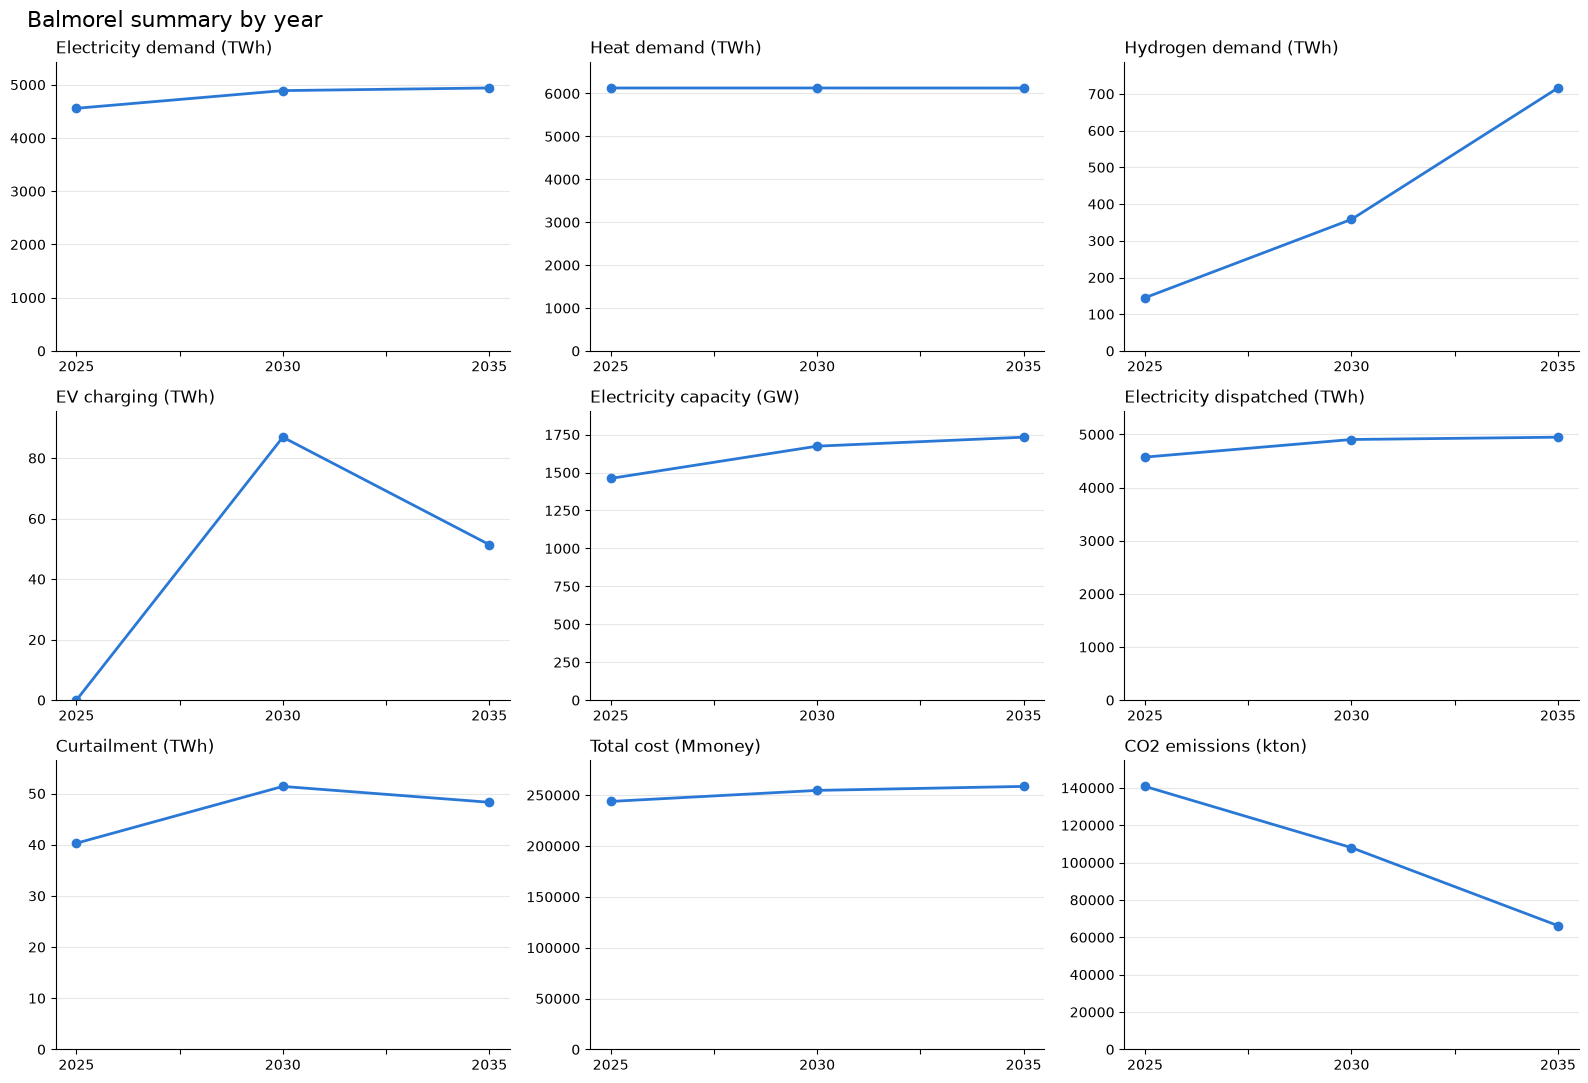

In [34]:
# Plot the summary metrics by year
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()

for ax, column in zip(axes, summary.columns):
    summary[column].plot(
        ax=ax,
        marker="o",
        linewidth=2,
        color="#2a78d6"
    )
    ax.set_ylim(0, summary[column].max() * 1.1)
    ax.ticklabel_format(style="plain", axis="y")
    ax.set_title(column, loc="left")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

for ax in axes[len(summary.columns):]:
    ax.remove()

plt.suptitle("Balmorel summary by year", fontsize=16, x=0.02, ha="left")
plt.tight_layout()
plt.show()

## 8. Comparison with the base_no_dc_8 scenario

This section compares the scenario containing this notebook with the sibling `base_no_dc_8` scenario for 2030 and 2035. The notebook can be copied into another scenario folder without changing these paths.

In [ ]:
# 8.1 Summary comparison and changes in electricity generation/capacity mix
COMPARISON_YEARS = ["2030", "2035"]
BASE_SCENARIO = "base_no_dc_8"
BASE_DIR = SCENARIO_DIR.parent / BASE_SCENARIO
BASE_RESULTS_DIR = BASE_DIR / "model"

if not BASE_RESULTS_DIR.exists():
    raise FileNotFoundError(f"Base scenario results not found: {BASE_RESULTS_DIR}")

base_res = MainResults(
    files=RESULTS,
    paths=str(BASE_RESULTS_DIR),
    scenario_names=[BASE_SCENARIO],
)

def scenario_result(results, scenario, symbol):
    return results.get_result(symbol).rename(columns=RENAME).query("Scenario == @scenario").copy()

def yearly_total(results, scenario, symbol):
    table = scenario_result(results, scenario, symbol)
    return table.groupby(table["Year"].astype(str))["Value"].sum().reindex(COMPARISON_YEARS).fillna(0)

def transmission_expansion(results, scenario):
    table = scenario_result(results, scenario, "X_CAP_YCR")
    table = table[table["Category"] == "ENDOGENOUS"]
    return table.groupby(table["Year"].astype(str))["Value"].sum().reindex(COMPARISON_YEARS).fillna(0)

def fuel_mix(results, scenario, symbol, commodity="ELECTRICITY"):
    table = scenario_result(results, scenario, symbol)
    table = table[table["Commodity"] == commodity]
    return table.groupby([table["Year"].astype(str), "Fuel"])["Value"].sum().unstack("Fuel").fillna(0).reindex(COMPARISON_YEARS).fillna(0)

metrics = {
    "Total cost (Mmoney)": "OBJ_YCR",
    "Transmission expansion (GW)": None,
    "CO2 emissions (kton)": "EMI_YCRAG",
    "Curtailment (TWh)": "CURT_YCRAGF",
}
comparison_rows = []
for label, symbol in metrics.items():
    if symbol is None:
        scenario_values = transmission_expansion(res, SCENARIO)
        base_values = transmission_expansion(base_res, BASE_SCENARIO)
    else:
        scenario_values = yearly_total(res, SCENARIO, symbol)
        base_values = yearly_total(base_res, BASE_SCENARIO, symbol)
    for year in COMPARISON_YEARS:
        base_value = base_values.loc[year]
        scenario_value = scenario_values.loc[year]
        comparison_rows.append({
            "Year": int(year),
            "Metric": label,
            "Base": base_value,
            "Scenario": scenario_value,
            "Change": scenario_value - base_value,
            "Change (%)": (scenario_value - base_value) / base_value * 100 if base_value else float("nan"),
        })

comparison = pd.DataFrame(comparison_rows).round({"Base": 2, "Scenario": 2, "Change": 2, "Change (%)": 2})
display(comparison)

for title, symbol in [("Electricity generation mix", "PRO_YCRAGF"), ("Electricity capacity mix", "G_CAP_YCRAF")]:
    scenario_mix = fuel_mix(res, SCENARIO, symbol)
    base_mix = fuel_mix(base_res, BASE_SCENARIO, symbol)
    fuels = scenario_mix.columns.union(base_mix.columns)
    scenario_mix = scenario_mix.reindex(columns=fuels, fill_value=0)
    base_mix = base_mix.reindex(columns=fuels, fill_value=0)
    scenario_pct = scenario_mix.div(scenario_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    base_pct = base_mix.div(base_mix.sum(axis=1).replace(0, float("nan")), axis=0) * 100
    change_pct = (scenario_pct - base_pct).fillna(0).round(2)
    print(f"{title}: percentage-point change (scenario minus base)")
    display(change_pct)

    ax = change_pct.T.plot.bar(figsize=(12, 5), width=0.8)
    ax.axhline(0, color="#444444", linewidth=0.8)
    ax.set_title(f"Change in {title.lower()} (scenario minus base)", loc="left")
    ax.set_ylabel("Percentage points")
    ax.set_xlabel("Fuel")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"): ax.spines[side].set_visible(False)
    plt.tight_layout(); plt.show()
